# Credit Risk — Final Test

Runs **once**, after model selection is finished. `artifacts/final_config.json` is not modified; the notebook stops if `artifacts/test_result.json` exists.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from modeling_utils import *

RESULT = ARTIFACTS / "test_result.json"
assert not RESULT.exists(), "The test set has already been used; re-running it requires a deliberate decision."
cfg = json.load(open(ARTIFACTS / "final_config.json"))
features = cfg["features"]
engine = get_engine()
df = load_split(engine, ["train", "val", "test"])
categories = {c: sorted(df[c].dropna().unique()) for c in cfg["categories"]}
dev, test = df[df["split"] != "test"].reset_index(drop=True), df[df["split"] == "test"].reset_index(drop=True)
kaggle = pd.read_sql("SELECT * FROM mart.features_application_test ORDER BY sk_id_curr", engine)
y_dev, y = dev[TARGET].to_numpy(), test[TARGET].to_numpy()
print(len(dev), len(test), len(kaggle), test[TARGET].mean().round(5))

246008 61503 48744 0.08073


In [2]:
X_dev, X_test, X_kaggle = [to_lgb_frame(f, features, categories) for f in (dev, test, kaggle)]
if cfg["encode_column"]:
    c = cfg["encode_column"]
    values = X_dev[c].astype(object).to_numpy()
    X_test[c] = target_encode(values, y_dev, X_test[c].astype(object).to_numpy())
    X_kaggle[c] = target_encode(values, y_dev, X_kaggle[c].astype(object).to_numpy())
    X_dev, _ = encode_fold(X_dev, y_dev, X_dev.iloc[:1], c)
model = lgb.LGBMClassifier(**{**LGB_PARAMS, **cfg["params"], "n_estimators": cfg["n_trees"]}).fit(X_dev, y_dev)
model.booster_.save_model(ARTIFACTS / "final_model.txt")

oof = pd.read_csv(ARTIFACTS / "oof.csv").merge(dev[[ID]], on=ID)["oof"].to_numpy()
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)
if cfg["calibration"] == "platt":
    cal = LogisticRegression(C=1e6).fit(logit(oof), y_dev)
    calibrate = lambda p: cal.predict_proba(logit(p))[:, 1]
elif cfg["calibration"] == "isotonic":
    cal = IsotonicRegression(out_of_bounds="clip").fit(oof, y_dev)
    calibrate = cal.predict
else:
    calibrate = lambda p: p
p_test = calibrate(model.predict_proba(X_test)[:, 1])
p_kaggle = calibrate(model.predict_proba(X_kaggle)[:, 1])

In [3]:
thr, credit = cfg["threshold"], test["amt_credit"].to_numpy()
metrics = score_metrics(y, p_test)
metrics["ECE"] = expected_calibration_error(y, p_test)
metrics["mean PD"] = float(p_test.mean()); metrics["observed rate"] = float(y.mean())
rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    boot.append(roc_auc_score(y[i], p_test[i]))
ci = np.percentile(boot, [2.5, 97.5])
policy = policy_row(y, p_test, credit, thr)
everyone = policy_row(y, p_test, credit, 1.01)
fair_gender = fairness_table(y, p_test, test["code_gender"].to_numpy(dtype=object), thr)
fair_age = fairness_table(y, p_test, age_band(test["days_birth"]), thr)
pd.DataFrame({"sk_id_curr": kaggle[ID], "TARGET": p_kaggle}).to_csv(ROOT / "data" / "submission.csv", index=False)
json.dump(dict(metrics=metrics, auc_ci_95=list(ci), policy=policy, approve_all=everyone, oof_metrics=cfg["oof_metrics"], oof_policy=cfg["oof_policy"]),
          open(RESULT, "w"), ensure_ascii=False, indent=1, default=float)
print(f"Test ROC-AUC {metrics['ROC-AUC']:.4f} (95% CI {ci[0]:.4f}-{ci[1]:.4f}) | CV {cfg['cv_auc']:.4f}")
pd.Series(metrics).round(4)

Test ROC-AUC 0.7893 (95% CI 0.7825-0.7962) | CV 0.7873


ROC-AUC          0.7893
Gini             0.5787
PR-AUC           0.2895
LogLoss          0.2357
Brier            0.0655
ECE              0.0019
mean PD          0.0798
observed rate    0.0807
dtype: float64

In [4]:
pd.DataFrame({"OOF": cfg["oof_policy"], "test": policy, "approve everyone (test)": everyone}).T.round(4)

,threshold,approval rate,default rate (approved),defaults rejected,profit / total credit
OOF,0.22,0.9203,0.0595,0.3219,0.1053
test,0.22,0.9202,0.0590,0.3277,0.1053
approve everyone (test),1.01,1.0000,0.0807,0.0000,0.1009


In [5]:
print(fair_gender.round(4).to_string()); fair_age.round(4)

         n  actual default rate  mean PD     AUC  approval rate  approval rate (good)  approval rate (bad)  default rate (approved)
F  40561.0               0.0699   0.0726  0.7838         0.9342                0.9511               0.7098                   0.0531
M  20940.0               0.1017   0.0937  0.7890         0.8929                0.9235               0.6224                   0.0709


,n,actual default rate,mean PD,AUC,approval rate,approval rate (good),approval rate (bad),default rate (approved)
30-44,24744.0,0.0883,0.0888,0.7985,0.9021,0.9282,0.6331,0.0620
45-59,20663.0,0.0685,0.0658,0.7803,0.9477,0.9630,0.7401,0.0535
60+,7191.0,0.0496,0.0479,0.7415,0.9804,0.9865,0.8627,0.0437
<30,8905.0,0.1130,0.1128,0.7659,0.8577,0.8913,0.5944,0.0783


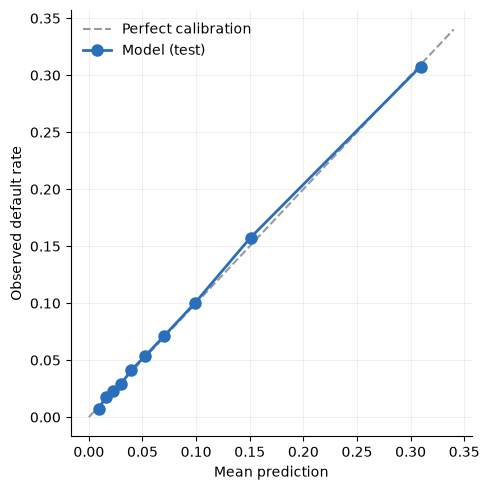

,mean_predicted,observed_rate,n
0,0.0091,0.0072,6151
1,0.0159,0.0177,6150
2,0.0223,0.0228,6150
3,0.0297,0.0286,6150
4,0.0392,0.0410,6151
5,0.0522,0.0533,6150
6,0.0704,0.0714,6150
7,0.0989,0.1002,6150
8,0.1508,0.1576,6150
9,0.3093,0.3076,6151


In [6]:
rel = reliability_table(y, p_test)
fig, ax = plt.subplots(figsize=(5, 5))
lim = max(rel.max(numeric_only=True)[["mean_predicted", "observed_rate"]]) * 1.1
ax.plot([0, lim], [0, lim], color="#9a9a9a", lw=1.5, ls="--", label="Perfect calibration")
ax.plot(rel["mean_predicted"], rel["observed_rate"], color="#2a6fbb", lw=2, marker="o", ms=8, label="Model (test)")
ax.set_xlabel("Mean prediction"); ax.set_ylabel("Observed default rate"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(ARTIFACTS / "calibration_test.png", dpi=130); plt.show()
rel.round(4)